In [1]:

# Import libraries for data analysis and SQL Server connectivity
import pandas as pd
import numpy as np
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

# Configure the SQL Server connection using Windows Authentication
connection_url = URL.create(
    "mssql+pyodbc",
    host="Sindhu",
    database="HospitalQualityAnalytics",
    query={
        "driver": "ODBC Driver 18 for SQL Server",
        "Trusted_Connection": "yes",
        "Encrypt": "yes",
        "TrustServerCertificate": "yes"
    }
)

# Create the database engine for subsequent analysis
engine = create_engine(connection_url)

# Test the connection by retrieving the active database name
with engine.connect() as connection:
    database_name = connection.execute(
        text("SELECT DB_NAME()")
    ).scalar()

print("Successfully connected to SQL Server!")
print("Connected Database:", database_name)


Successfully connected to SQL Server!
Connected Database: HospitalQualityAnalytics


In [2]:

# Load the cleaned hospital quality dataset from SQL Server
# This view contains all 20 quality measures across hospitals

query = """
SELECT *
FROM dbo.vw_HospitalQualityClean
"""

# Retrieve the SQL data into a pandas DataFrame
with engine.connect() as connection:
    df = pd.read_sql_query(text(query), connection)

# Display the dataset dimensions
print("Dataset loaded successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

# Preview the first five records
display(df.head())


Dataset loaded successfully!
Total Rows: 95800
Total Columns: 16


,Facility_ID,Facility_Name,State,City_Town,ZIP_Code,Measure_ID,Measure_Name,Score_Numeric,Score_Raw,Denominator_Numeric,Lower_Estimate_Numeric,Higher_Estimate_Numeric,Footnote,Start_Date,End_Date,Score_Status
0,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,3.8,3.8,33.0,NaN,NaN,NaN,2023-04-01,2025-03-31,Available
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,Hybrid_HWM,Hybrid Hospital-Wide All-Cause Risk Standardiz...,4.4,4.4,4972.0,NaN,NaN,NaN,2024-07-01,2025-06-30,Available
2,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,MORT_30_AMI,Death rate for heart attack patients,13.5,13.5,234.0,NaN,NaN,NaN,2022-07-01,2025-06-30,Available
3,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,MORT_30_CABG,Death rate for CABG surgery patients,3.2,3.2,127.0,NaN,NaN,NaN,2022-07-01,2025-06-30,Available
4,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,DOTHAN,36301,MORT_30_COPD,Death rate for COPD patients,9.1,9.1,116.0,NaN,NaN,NaN,2022-07-01,2025-06-30,Available


In [3]:

# Calculate missing values for every column in the SQL dataset
missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2)
})

# Sort columns by the highest percentage of missing values
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)

# Display the data quality summary
display(missing_summary)


,Missing_Count,Missing_Percentage
Lower_Estimate_Numeric,63904,66.71
Higher_Estimate_Numeric,63904,66.71
Footnote,51217,53.46
Denominator_Numeric,46316,48.35
Score_Numeric,43408,45.31
Facility_ID,0,0.00
State,0,0.00
Facility_Name,0,0.00
Measure_Name,0,0.00
Measure_ID,0,0.00


In [4]:

# Group hospital records by quality measure
# Calculate reporting completeness for each measure
measure_availability = (
    df.groupby(["Measure_ID", "Measure_Name"])
    .agg(
        Total_Records=("Score_Numeric", "size"),
        Available_Scores=("Score_Numeric", "count")
    )
    .reset_index()
)

# Calculate unavailable scores and availability percentage
measure_availability["Missing_Scores"] = (
    measure_availability["Total_Records"]
    - measure_availability["Available_Scores"]
)

measure_availability["Availability_Percentage"] = (
    measure_availability["Available_Scores"]
    / measure_availability["Total_Records"] * 100
).round(2)

# Sort measures from lowest to highest reporting availability
measure_availability = measure_availability.sort_values(
    "Availability_Percentage"
)

# Display reporting completeness across all quality measures
display(measure_availability)


,Measure_ID,Measure_Name,Total_Records,Available_Scores,Missing_Scores,Availability_Percentage
3,MORT_30_CABG,Death rate for CABG surgery patients,4790,861,3929,17.97
9,PSI_04,Death rate among surgical inpatients with seri...,4790,1521,3269,31.75
0,COMP_HIP_KNEE,Rate of complications for hip/knee replacement...,4790,1706,3084,35.62
2,MORT_30_AMI,Death rate for heart attack patients,4790,1935,2855,40.40
16,PSI_13,Postoperative sepsis rate,4790,2406,2384,50.23
7,MORT_30_STK,Death rate for stroke patients,4790,2422,2368,50.56
13,PSI_10,Postoperative acute kidney injury requiring di...,4790,2452,2338,51.19
14,PSI_11,Postoperative respiratory failure rate,4790,2461,2329,51.38
17,PSI_14,Postoperative wound dehiscence rate,4790,2474,2316,51.65
4,MORT_30_COPD,Death rate for COPD patients,4790,2623,2167,54.76


In [5]:

# Select the hospital-wide mortality measure for deeper analysis
mortality_df = df.loc[
    df["Measure_ID"] == "Hybrid_HWM"
].copy()

# Convert SQL Server decimal values to numeric pandas values
# Missing scores remain NaN rather than being replaced with zero
mortality_df["Mortality_Rate"] = pd.to_numeric(
    mortality_df["Score_Numeric"],
    errors="coerce"
)

# Verify the selected dataset and score availability
print("Total Hospital Records:", len(mortality_df))
print("Available Mortality Scores:", mortality_df["Mortality_Rate"].notna().sum())
print("Missing Mortality Scores:", mortality_df["Mortality_Rate"].isna().sum())
print("Unique Hospitals:", mortality_df["Facility_ID"].nunique())

# Preview the selected hospital mortality records
display(
    mortality_df[
        ["Facility_ID", "Facility_Name", "State", "Mortality_Rate"]
    ].head()
)


Total Hospital Records: 4790
Available Mortality Scores: 4261
Missing Mortality Scores: 529
Unique Hospitals: 4790


,Facility_ID,Facility_Name,State,Mortality_Rate
1,010001,SOUTHEAST HEALTH MEDICAL CENTER,AL,4.4
21,010005,MARSHALL MEDICAL CENTERS,AL,5.7
41,010006,NORTH ALABAMA MEDICAL CENTER,AL,5.1
61,010007,MIZELL MEMORIAL HOSPITAL,AL,6.7
81,010011,ST. VINCENT'S EAST,AL,4.3


In [8]:

# Select hospitals with valid numeric mortality scores
# Missing values are excluded from descriptive calculations
valid_scores = mortality_df["Mortality_Rate"].dropna()

# Calculate descriptive statistics to understand
# the distribution of reported hospital mortality rates
statistics_summary = pd.Series({
    "Count": valid_scores.count(),
    "Mean": valid_scores.mean(),
    "Median": valid_scores.median(),
    "Standard Deviation": valid_scores.std(),
    "Minimum": valid_scores.min(),
    "25th Percentile": valid_scores.quantile(0.25),
    "75th Percentile": valid_scores.quantile(0.75),
    "Maximum": valid_scores.max(),
    "Skewness": valid_scores.skew()
})

# Display the summary rounded to two decimal places
display(statistics_summary.round(2))


Count                 4261.00
Mean                     4.04
Median                   3.90
Standard Deviation       0.84
Minimum                  1.60
25th Percentile          3.50
75th Percentile          4.40
Maximum                 12.80
Skewness                 1.92
dtype: float64

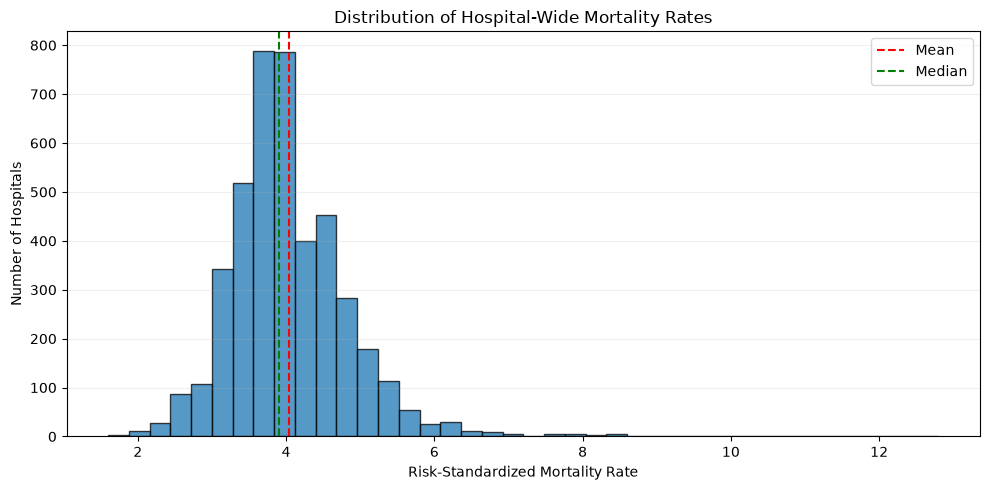

In [9]:

# Import Matplotlib for statistical visualization
import matplotlib.pyplot as plt

# Select hospitals with valid mortality scores
valid_scores = mortality_df["Mortality_Rate"].dropna()

# Create a histogram to examine the distribution of mortality scores
plt.figure(figsize=(10, 5))
plt.hist(valid_scores, bins=40, edgecolor="black", alpha=0.75)

# Add reference lines for the mean and median
plt.axvline(valid_scores.mean(), color="red",
            linestyle="--", label="Mean")
plt.axvline(valid_scores.median(), color="green",
            linestyle="--", label="Median")

# Add descriptive labels and a legend
plt.title("Distribution of Hospital-Wide Mortality Rates")
plt.xlabel("Risk-Standardized Mortality Rate")
plt.ylabel("Number of Hospitals")
plt.legend()
plt.grid(axis="y", alpha=0.2)

# Display the completed distribution chart
plt.tight_layout()
plt.show()


In [10]:

# Calculate the first and third quartiles of mortality scores
Q1 = valid_scores.quantile(0.25)
Q3 = valid_scores.quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Define conventional IQR thresholds for potential outliers
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify hospitals with scores outside the IQR thresholds
outliers = mortality_df[
    mortality_df["Mortality_Rate"].notna()
    & (
        (mortality_df["Mortality_Rate"] < lower_bound)
        | (mortality_df["Mortality_Rate"] > upper_bound)
    )
].copy()

# Display the calculated thresholds and number of outliers
print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))
print("Total Outliers:", len(outliers))
print("Outlier Percentage:", round(len(outliers) / len(valid_scores) * 100, 2), "%")


Q1: 3.5
Q3: 4.4
IQR: 0.9
Lower Bound: 2.15
Upper Bound: 5.75
Total Outliers: 138
Outlier Percentage: 3.24 %


In [11]:

# Count hospitals with available mortality scores in each state
state_hospitals = (
    mortality_df[mortality_df["Mortality_Rate"].notna()]
    .groupby("State")
    .size()
    .rename("Hospitals_With_Scores")
)

# Count hospitals flagged as outliers in each state
state_outliers = (
    outliers.groupby("State")
    .size()
    .rename("Outlier_Hospitals")
)

# Combine state hospital counts and outlier counts
state_outlier_summary = pd.concat(
    [state_hospitals, state_outliers],
    axis=1
).fillna(0)

# Calculate the percentage of hospitals flagged within each state
state_outlier_summary["Outlier_Percentage"] = (
    state_outlier_summary["Outlier_Hospitals"]
    / state_outlier_summary["Hospitals_With_Scores"] * 100
).round(2)

# Sort states by the number of flagged hospitals
state_outlier_summary = (
    state_outlier_summary
    .sort_values("Outlier_Hospitals", ascending=False)
    .reset_index()
)

# Display states with at least one flagged hospital
display(
    state_outlier_summary[
        state_outlier_summary["Outlier_Hospitals"] > 0
    ].head(15)
)


,State,Hospitals_With_Scores,Outlier_Hospitals,Outlier_Percentage
0,PR,45,36.0,80.00
1,KY,87,9.0,10.34
2,CA,305,7.0,2.30
3,MS,78,7.0,8.97
4,TN,91,6.0,6.59
5,NY,149,5.0,3.36
6,GA,116,5.0,4.31
7,PA,149,5.0,3.36
8,MA,57,4.0,7.02
9,AR,68,4.0,5.88


In [12]:

# Separate hospitals in Puerto Rico from all other locations
pr_scores = mortality_df.loc[
    mortality_df["State"] == "PR", "Mortality_Rate"
].dropna()

other_scores = mortality_df.loc[
    mortality_df["State"] != "PR", "Mortality_Rate"
].dropna()

# Calculate descriptive statistics for both groups
comparison_summary = pd.DataFrame({
    "Puerto Rico": {
        "Hospitals": len(pr_scores),
        "Mean": pr_scores.mean(),
        "Median": pr_scores.median(),
        "Std Dev": pr_scores.std(),
        "Minimum": pr_scores.min(),
        "Maximum": pr_scores.max()
    },
    "Other Locations": {
        "Hospitals": len(other_scores),
        "Mean": other_scores.mean(),
        "Median": other_scores.median(),
        "Std Dev": other_scores.std(),
        "Minimum": other_scores.min(),
        "Maximum": other_scores.max()
    }
})

# Display the group comparison rounded to two decimals
display(comparison_summary.round(2))


,Puerto Rico,Other Locations
Hospitals,45.00,4216.00
Mean,7.47,4.00
Median,7.60,3.90
Std Dev,2.09,0.74
Minimum,3.40,1.60
Maximum,12.80,8.40


In [13]:

# Import the Mann-Whitney U test from SciPy
from scipy.stats import mannwhitneyu

# Test whether mortality score distributions differ
# between Puerto Rico and all other locations
u_statistic, p_value = mannwhitneyu(
    pr_scores,
    other_scores,
    alternative="two-sided"
)

# Display the statistical test results
print("Mann-Whitney U Statistic:", round(u_statistic, 2))
print("P-value:", f"{p_value:.6e}")

# Interpret the result using a 5% significance level
alpha = 0.05

if p_value < alpha:
    print("Result: Statistically significant difference.")
else:
    print("Result: No statistically significant difference detected.")


Mann-Whitney U Statistic: 181920.0
P-value: 2.485781e-26
Result: Statistically significant difference.


In [14]:

# Calculate the sample sizes for both comparison groups
n_pr = len(pr_scores)
n_other = len(other_scores)

# Calculate the probability that a randomly selected
# Puerto Rico score exceeds a randomly selected score
# from another location, counting ties as half
probability_superiority = u_statistic / (n_pr * n_other)

# Calculate rank-biserial correlation as an effect size
# Positive values indicate higher scores in Puerto Rico
rank_biserial = 2 * probability_superiority - 1

# Calculate the difference between group medians
median_difference = pr_scores.median() - other_scores.median()

# Display effect size and practical comparison metrics
print("Probability of Superiority:",
      f"{probability_superiority * 100:.2f}%")

print("Rank-Biserial Correlation:",
      round(rank_biserial, 4))

print("Median Difference:",
      round(median_difference, 2))


Probability of Superiority: 95.89%
Rank-Biserial Correlation: 0.9178
Median Difference: 3.7


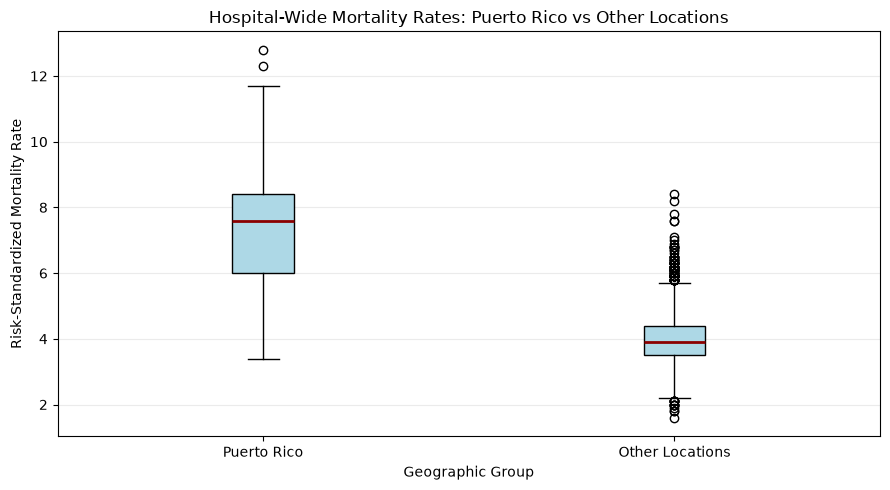

In [15]:

# Import Matplotlib for statistical visualization
import matplotlib.pyplot as plt

# Create a boxplot comparing mortality score distributions
# for Puerto Rico and all other locations
fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    [pr_scores, other_scores],
    tick_labels=["Puerto Rico", "Other Locations"],
    patch_artist=True,
    boxprops={"facecolor": "lightblue"},
    medianprops={"color": "darkred", "linewidth": 2}
)

# Add labels to make the chart understandable to stakeholders
ax.set_title("Hospital-Wide Mortality Rates: Puerto Rico vs Other Locations")
ax.set_ylabel("Risk-Standardized Mortality Rate")
ax.set_xlabel("Geographic Group")

# Add a subtle grid to support visual comparisons
ax.grid(axis="y", alpha=0.25)

# Display the completed comparison chart
plt.tight_layout()
plt.show()


In [16]:

# Calculate state-level mortality statistics using valid scores
state_summary = (
    mortality_df.groupby("State")
    .agg(
        Total_Hospitals=("Facility_ID", "count"),
        Hospitals_With_Scores=("Mortality_Rate", "count"),
        Average_Mortality=("Mortality_Rate", "mean"),
        Median_Mortality=("Mortality_Rate", "median")
    )
    .reset_index()
)

# Calculate score availability for each state
state_summary["Availability_Percentage"] = (
    state_summary["Hospitals_With_Scores"]
    / state_summary["Total_Hospitals"] * 100
).round(2)

# Restrict comparisons to locations with at least 30 scores
# This reduces instability from very small samples
state_comparison = state_summary[
    state_summary["Hospitals_With_Scores"] >= 30
].copy()

# Rank locations by their average reported mortality score
state_comparison = state_comparison.sort_values(
    "Average_Mortality",
    ascending=False
)

# Display the highest-average locations
display(state_comparison.head(10).round(2))


,State,Total_Hospitals,Hospitals_With_Scores,Average_Mortality,Median_Mortality,Availability_Percentage
42,PR,55,45,7.47,7.60,81.82
28,MS,99,78,4.72,4.60,78.79
1,AL,90,79,4.66,4.60,87.78
19,KY,93,87,4.54,4.50,93.55
2,AR,80,68,4.44,4.30,85.00
20,LA,115,98,4.41,4.20,85.22
46,TN,101,91,4.36,4.20,90.10
18,KS,134,118,4.35,4.25,88.06
14,IA,114,111,4.35,4.30,97.37
32,NE,91,80,4.26,4.20,87.91


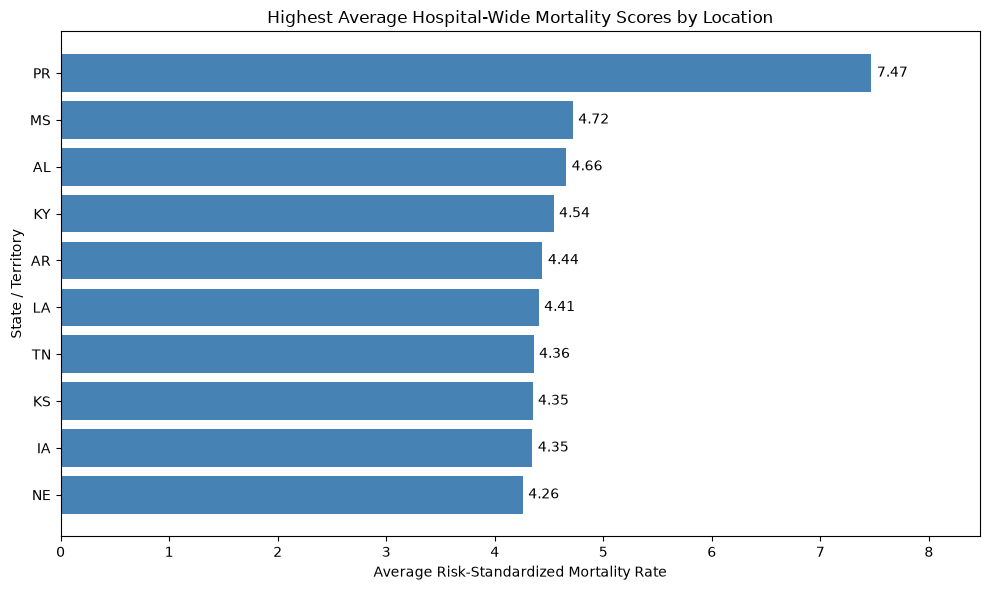

In [17]:

# Select the ten locations with the highest average mortality scores
top_states = state_comparison.head(10).sort_values(
    "Average_Mortality",
    ascending=True
)

# Create a horizontal bar chart for geographic comparison
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_states["State"],
    top_states["Average_Mortality"],
    color="steelblue"
)

# Add the average mortality score beside each bar
for bar in bars:
    ax.text(
        bar.get_width() + 0.05,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}",
        va="center"
    )

# Add labels and a descriptive title
ax.set_title("Highest Average Hospital-Wide Mortality Scores by Location")
ax.set_xlabel("Average Risk-Standardized Mortality Rate")
ax.set_ylabel("State / Territory")

# Leave room for numeric labels
ax.set_xlim(0, top_states["Average_Mortality"].max() + 1)

# Display the chart
plt.tight_layout()
plt.show()


In [18]:

# Select locations with at least 30 hospitals to avoid
# emphasizing availability percentages from very small groups
state_availability = state_summary[
    state_summary["Total_Hospitals"] >= 30
].copy()

# Identify the ten locations with the lowest score availability
lowest_availability = (
    state_availability
    .sort_values("Availability_Percentage", ascending=True)
    .head(10)
)

# Display hospital counts and score availability
display(
    lowest_availability[
        [
            "State",
            "Total_Hospitals",
            "Hospitals_With_Scores",
            "Availability_Percentage"
        ]
    ]
)


,State,Total_Hospitals,Hospitals_With_Scores,Availability_Percentage
29,MT,62,38,61.29
47,TX,406,312,76.85
28,MS,99,78,78.79
42,PR,55,45,81.82
31,ND,45,37,82.22
39,OK,124,102,82.26
2,AR,80,68,85.00
20,LA,115,98,85.22
11,GA,136,116,85.29
45,SD,60,52,86.67


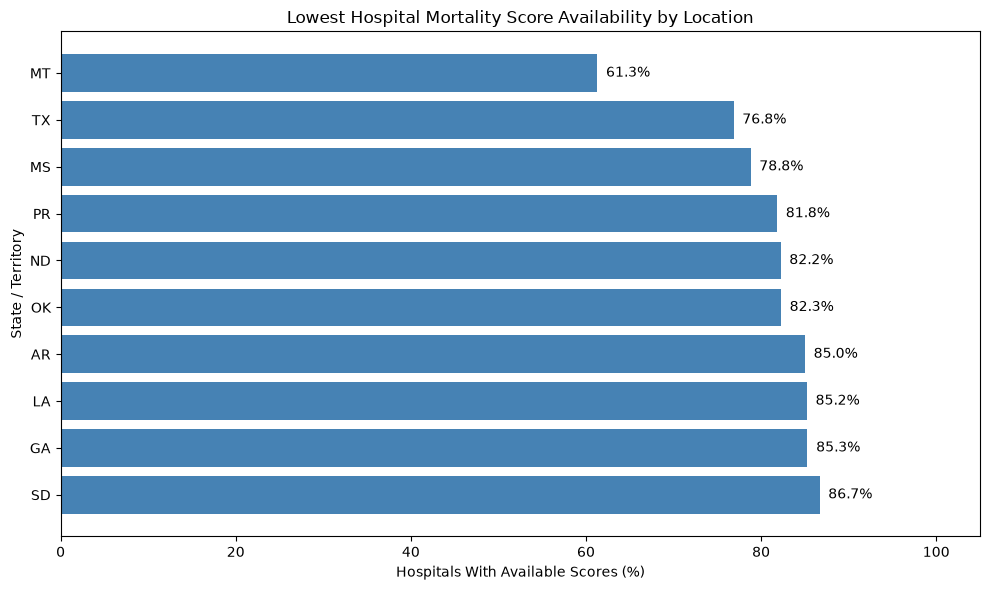

: 

In [ ]:

# Arrange the ten lowest-availability locations for a horizontal chart
availability_chart = lowest_availability.sort_values(
    "Availability_Percentage",
    ascending=True
)

# Create a horizontal bar chart of hospital mortality score availability
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    availability_chart["State"],
    availability_chart["Availability_Percentage"],
    color="steelblue"
)

# Label each bar with its availability percentage
for bar in bars:
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}%",
        va="center"
    )

# Add chart titles and axis labels
ax.set_title("Lowest Hospital Mortality Score Availability by Location")
ax.set_xlabel("Hospitals With Available Scores (%)")
ax.set_ylabel("State / Territory")
ax.set_xlim(0, 105)

# Put the lowest-availability location at the top
ax.invert_yaxis()

# Display the chart
plt.tight_layout()
plt.show()


## Statistical Analysis — Key Findings

### Dataset Overview
- Analyzed 95,800 hospital-quality records covering 4,790 hospitals and 20 quality measures.
- Selected the Hybrid Hospital-Wide Mortality measure (`Hybrid_HWM`) for detailed analysis because it had the highest numeric score availability (88.96%).
- Of 4,790 hospital records for this measure, 4,261 had available mortality scores.

### Mortality Score Distribution
- Mean mortality score: 4.04.
- Median mortality score: 3.90.
- Standard deviation: 0.84.
- Skewness: 1.92, indicating a right-skewed distribution.
- The IQR method identified 138 potential outliers (3.24% of hospitals with available scores).

### Geographic Findings
- Puerto Rico had the highest average reported mortality score among locations with at least 30 available scores (7.47).
- Mississippi (4.72) and Alabama (4.66) followed.
- In Puerto Rico, 36 of 45 hospitals with available scores exceeded the overall IQR outlier threshold.

### Statistical Testing
- A two-sided Mann–Whitney U test identified a statistically significant difference between Puerto Rico and other locations (U = 181,920; p = 2.49 × 10⁻²⁶).
- The rank-biserial correlation was 0.9178, indicating a large observed difference.
- The median mortality score difference was 3.70 points.

### Data Quality Findings
- Overall numeric score availability across all 20 measures was 54.69%.
- Hospital-wide mortality score availability was 88.96%.
- Among locations with at least 30 hospitals, Montana had the lowest hospital-wide mortality score availability (61.29%).

### Limitations
- Missing scores may reflect reporting eligibility, suppression, or other measure-specific conditions; their causes have not been established.
- Geographic comparisons are observational and do not establish causation.
- Hospital-level averages are not population mortality rates.
- Differences in hospital characteristics, patient populations, and reporting may influence comparisons.
- Findings describe one specific risk-standardized mortality measure and should not be interpreted as overall hospital-quality rankings.
- The Puerto Rico comparison was selected after exploratory review, so its p-value should be interpreted as exploratory rather than confirmatory.